## 1. Import packages and set folders

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
import statsmodels.api as sm
from IPython.display import display

# Locate the repository from the current folder (repository root or code/).
working_folder = Path.cwd().resolve()
project_folder = next(
    (folder for folder in (working_folder, *working_folder.parents)
     if all((folder / name).is_dir() for name in ("code", "dataset_raw", "dataset_analysis"))),
    None,
)
if project_folder is None:
    raise FileNotFoundError(
        "Open Jupyter from the repository root or its code folder. "
        "Expected code/, dataset_raw/, and dataset_analysis/."
    )
output_folder = project_folder / "output"
data_folder = project_folder / "dataset_analysis"

analysis_years = list(range(1995, 2025))
comparison_years = [1995, 2024]
insurance_sectors = ["Life", "Non-life", "Total"]

def read_numeric(values):
    text = values.str.strip().str.lstrip("'")
    return pd.to_numeric(text.mask(text.eq("")), errors="raise")

## 2. Read the prepared files

Read the imputed premiums from notebook 03 and GDP/population from notebook 02.
Convert premiums from USD millions to USD. Keep blank amounts as missing, not zero.

In [3]:
imputed_data_file = data_folder / "03_imputed_insurance_rows_python.csv"
insurance_rows = pd.read_csv(imputed_data_file, dtype=str, keep_default_na=False)
gdp_data = pd.read_csv(data_folder / "02_worldbank_gdp.csv", dtype=str, keep_default_na=False)
population_data = pd.read_csv(data_folder / "02_worldbank_population_total.csv", dtype=str, keep_default_na=False)

assert gdp_data["Indicator Code"].eq("NY.GDP.PCAP.PP.KD").all()
assert population_data["Indicator Code"].eq("SP.POP.TOTL").all()
assert insurance_rows["UNIT_MULT"].eq("6").all()

analysis_country_names = insurance_rows[["REF_AREA", "Reference area"]].drop_duplicates()
analysis_country_names = analysis_country_names.rename(columns={"REF_AREA": "country_code", "Reference area": "country"})

premium_rows = pd.DataFrame({
    "country_code": insurance_rows["REF_AREA"],
    "year": insurance_rows["TIME_PERIOD"].astype(int),
    "sector": insurance_rows["insurance type_analysis"],
    "business": insurance_rows["Insurance business"],
    "premium_usd": read_numeric(insurance_rows["OBS_VALUE_imputed"]) * 1000000,
    "original_premium_usd": read_numeric(insurance_rows["OBS_VALUE"]) * 1000000,
    "use_after_imputation": insurance_rows["used_in_sum_after"].str.upper().eq("TRUE"),
    "use_before_imputation": insurance_rows["used_in_sum"].str.upper().eq("TRUE"),
    "is_estimated": insurance_rows["is_imputed"].str.upper().eq("TRUE"),
    "aggregation_source": insurance_rows["aggregation_source_after"],
})
display(premium_rows.head())

,country_code,year,sector,business,premium_usd,original_premium_usd,use_after_imputation,use_before_imputation,is_estimated,aggregation_source
0,AUS,2012,Non-life,Reinsurance accepted,NaN,NaN,False,False,False,Missing
1,AUS,2013,Non-life,Reinsurance accepted,NaN,NaN,False,False,False,Missing
2,AUS,2014,Non-life,Reinsurance accepted,NaN,NaN,False,False,False,Missing
3,AUS,2015,Non-life,Reinsurance accepted,NaN,NaN,False,False,False,Missing
4,SWE,2015,Non-life,Reinsurance accepted,NaN,NaN,False,False,False,Missing


## 3. Calculate Life and Non-life premiums

Use the component-selection flags from imputation. Do not add reported business
Totals to their components. `min_count=1` leaves an all-missing sum missing.
Available amounts can still be partial sums.

In [4]:
group_columns = ["country_code", "year", "sector"]

selected_after = premium_rows.loc[premium_rows["use_after_imputation"]]
gwp = selected_after.groupby(group_columns)["premium_usd"].sum(min_count=1).rename("gwp")

selected_before = premium_rows.loc[premium_rows["use_before_imputation"]]
original_gwp = selected_before.groupby(group_columns)["original_premium_usd"].sum(min_count=1).rename("original_gwp")

direct_rows = premium_rows.loc[premium_rows["business"].eq("Direct business")]
direct_premiums = direct_rows.groupby(group_columns)["premium_usd"].sum(min_count=1).rename("direct_premiums")

premium_rows["estimated_contributor"] = premium_rows["use_after_imputation"] & premium_rows["is_estimated"]
includes_estimates = premium_rows.groupby(group_columns)["estimated_contributor"].any().rename("includes_estimates")

country_year_grid = pd.MultiIndex.from_product(
    [analysis_country_names["country_code"], analysis_years, ["Life", "Non-life"]],
    names=group_columns,
)

sector_premiums = pd.concat([gwp, original_gwp, direct_premiums, includes_estimates], axis=1)
sector_premiums = sector_premiums.reindex(country_year_grid).reset_index()
sector_premiums["includes_estimates"] = sector_premiums["includes_estimates"].eq(True)
display(sector_premiums.head())

,country_code,year,sector,gwp,original_gwp,direct_premiums,includes_estimates
0,AUS,1995,Life,1.614361e+10,NaN,1.613163e+10,True
1,AUS,1995,Non-life,1.412092e+10,1.412092e+10,1.208692e+10,False
2,AUS,1996,Life,1.608708e+10,1.608708e+10,1.608708e+10,False
3,AUS,1996,Non-life,1.657239e+10,1.657239e+10,1.425972e+10,False
4,AUS,1997,Life,2.165093e+10,2.165093e+10,2.138239e+10,False


## 4. Add Total premiums, GDP and population

Total combines available Life and Non-life amounts. Join countries by code and year.
GWP per capita includes accepted reinsurance, but direct premiums per capita do not.

In [5]:
amount_columns = ["gwp", "original_gwp", "direct_premiums"]
total_premiums = sector_premiums.groupby(["country_code", "year"])[amount_columns].sum(min_count=1)
total_premiums["includes_estimates"] = sector_premiums.groupby(["country_code", "year"])["includes_estimates"].any()
total_premiums = total_premiums.reset_index()
total_premiums["sector"] = "Total"
premium_panel = pd.concat([sector_premiums, total_premiums], ignore_index=True)

year_columns = [str(year) for year in analysis_years]
gdp_long = gdp_data.melt(id_vars="Country Code", value_vars=year_columns,
                         var_name="year", value_name="gdp_per_capita")
gdp_long = gdp_long.rename(columns={"Country Code": "country_code"})
gdp_long["year"] = gdp_long["year"].astype(int)
gdp_long["gdp_per_capita"] = read_numeric(gdp_long["gdp_per_capita"])

population_long = population_data.melt(id_vars="Country Code", value_vars=year_columns,
                                       var_name="year", value_name="population")
population_long = population_long.rename(columns={"Country Code": "country_code"})
population_long["year"] = population_long["year"].astype(int)
population_long["population"] = read_numeric(population_long["population"])

premium_panel = premium_panel.merge(analysis_country_names, on="country_code", how="left", validate="many_to_one")
premium_panel = premium_panel.merge(gdp_long, on=["country_code", "year"], how="left", validate="many_to_one")
premium_panel = premium_panel.merge(population_long, on=["country_code", "year"], how="left", validate="many_to_one")
premium_panel["gwp_per_capita"] = premium_panel["gwp"] / premium_panel["population"]
premium_panel["direct_per_capita"] = premium_panel["direct_premiums"] / premium_panel["population"]

# Log-based analyses require positive, finite premiums and macroeconomic values.
required_values = premium_panel[["gwp", "gdp_per_capita", "population"]]
premium_panel["usable_gwp"] = (np.isfinite(required_values) & required_values.gt(0)).all(axis=1)
premium_panel["usable_direct"] = (
    premium_panel["usable_gwp"] & np.isfinite(premium_panel["direct_per_capita"])
    & premium_panel["direct_per_capita"].gt(0)
)

## 5. Select fixed analysis samples

For trends, require usable GWP in every year and all three sectors. For direct comparisons, additionally require direct premiums in both endpoint years and all sectors. 
Current sample counts are 30 preparation countries, 28 GWP countries and 27 direct countries.

In [6]:
gwp_country_check = premium_panel.groupby(["country_code", "country"])["usable_gwp"].agg(["size", "all"])
gwp_country_check["keep_country"] = gwp_country_check["size"].eq(len(analysis_years) * 3) & gwp_country_check["all"]
gwp_country_check = gwp_country_check.reset_index()[["country_code", "country", "keep_country"]]
gwp_country_codes = gwp_country_check.loc[gwp_country_check["keep_country"], "country_code"].tolist()

trend_panel = premium_panel.loc[premium_panel["country_code"].isin(gwp_country_codes)].copy()
endpoint_panel = trend_panel.loc[trend_panel["year"].isin(comparison_years)].copy()
direct_country_check = endpoint_panel.groupby(["country_code", "country"])["usable_direct"].all().reset_index(name="keep_country")
direct_country_codes = direct_country_check.loc[direct_country_check["keep_country"], "country_code"].tolist()
direct_endpoint_panel = endpoint_panel.loc[endpoint_panel["country_code"].isin(direct_country_codes)].copy()

sample_counts = pd.DataFrame({
    "sample": ["Preparation", "Fixed GWP", "Matched direct premiums"],
    "countries": [len(analysis_country_names), len(gwp_country_codes), len(direct_country_codes)],
})

display(sample_counts)
display(gwp_country_check.loc[~gwp_country_check["keep_country"]])
display(direct_country_check.loc[~direct_country_check["keep_country"]])

,sample,countries
0,Preparation,30
1,Fixed GWP,28
2,Matched direct premiums,27


,country_code,country,keep_country
23,NZL,New Zealand,False
26,SVK,Slovak Republic,False


,country_code,country,keep_country
11,GBR,United Kingdom,False


## 6. Calculate annual levels and indices

Premium levels are country sums in nominal USD billions. GDP per capita is a population-weighted average using one row per country/year. Each index starts at 100 in 1995. Nominal premiums and real PPP GDP per capita do not measure growth on the same price basis.

In [7]:
annual_premiums = trend_panel.groupby(["year", "sector"])["gwp"].sum().div(1000000000).reset_index(name="value")
annual_premiums = annual_premiums.rename(columns={"sector": "indicator"})
annual_premiums["panel"] = "GWP (nominal USD billions)"

macro_rows = trend_panel.loc[trend_panel["sector"].eq("Total")].copy()
macro_rows["weighted_gdp"] = macro_rows["gdp_per_capita"] * macro_rows["population"]

annual_gdp = macro_rows.groupby("year")[["weighted_gdp", "population"]].sum()
annual_gdp["value"] = annual_gdp["weighted_gdp"] / annual_gdp["population"]
annual_gdp = annual_gdp[["value"]].reset_index()
annual_gdp["indicator"] = "GDP per capita"
annual_gdp["panel"] = "GDP per capita (constant 2021 PPP dollars)"

annual_trends = pd.concat([annual_premiums, annual_gdp], ignore_index=True)
annual_trends = annual_trends.sort_values(["indicator", "year"])
starting_values = annual_trends.loc[annual_trends["year"].eq(1995)].set_index("indicator")["value"]
annual_trends["index_1995"] = 100 * annual_trends["value"] / annual_trends["indicator"].map(starting_values)
display(annual_trends.loc[annual_trends["year"].isin(comparison_years)].round(3))

indicator_colors = {"Life": "#286b98", "Non-life": "#cf762c", "Total": "#243b53", "GDP per capita": "#3b8b76"}

,year,indicator,value,panel,index_1995
90,1995,GDP per capita,36698.223,GDP per capita (constant 2021 PPP dollars),100.000
119,2024,GDP per capita,55899.949,GDP per capita (constant 2021 PPP dollars),152.323
0,1995,Life,962.781,GWP (nominal USD billions),100.000
87,2024,Life,3261.462,GWP (nominal USD billions),338.754
1,1995,Non-life,1011.157,GWP (nominal USD billions),100.000
88,2024,Non-life,3962.750,GWP (nominal USD billions),391.902
2,1995,Total,1973.938,GWP (nominal USD billions),100.000
89,2024,Total,7224.212,GWP (nominal USD billions),365.980


## 7. Plot insurance premium levels

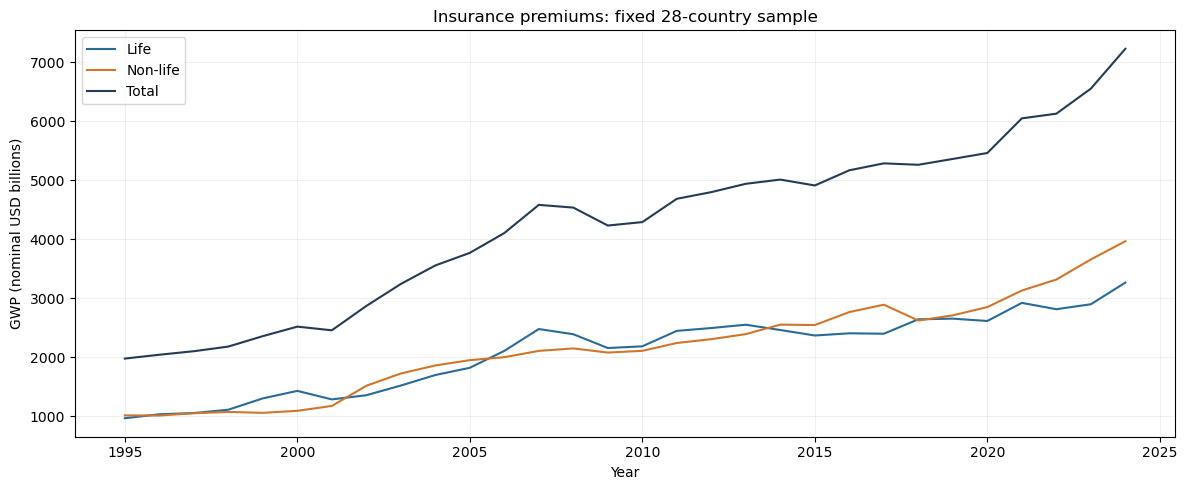

In [8]:
fig, ax = plt.subplots(figsize=(12, 5))
for sector in insurance_sectors:
    rows = annual_premiums.loc[annual_premiums["indicator"].eq(sector)]
    ax.plot(rows["year"], rows["value"], color=indicator_colors[sector], label=sector)
ax.set(title=f"Insurance premiums: fixed {len(gwp_country_codes)}-country sample",
       xlabel="Year", ylabel="GWP (nominal USD billions)")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()

plt.show()
plt.close(fig)

## 8. Plot population-weighted GDP per capita

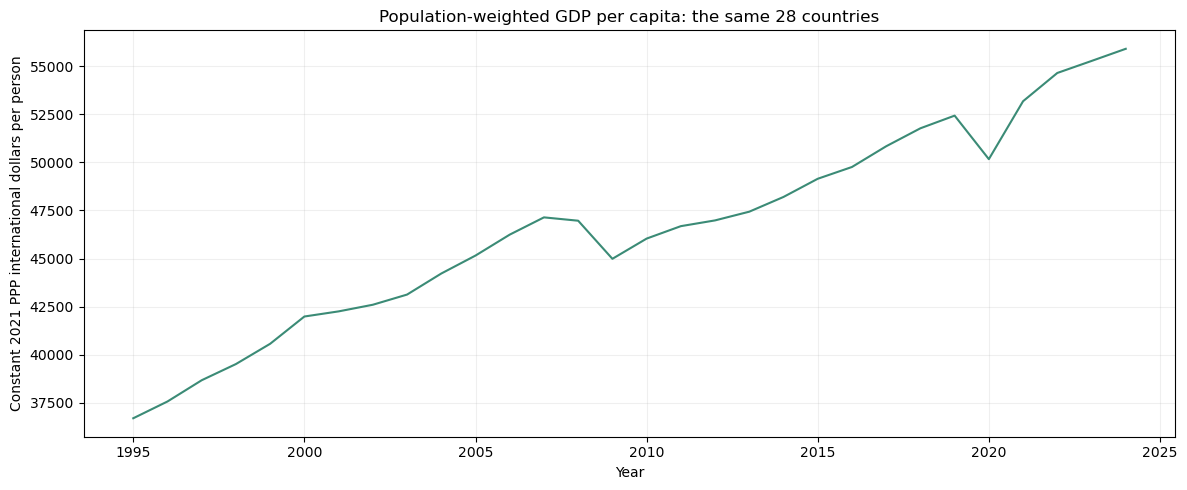

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(annual_gdp["year"], annual_gdp["value"], color=indicator_colors["GDP per capita"])
ax.set(title=f"Population-weighted GDP per capita: the same {len(gwp_country_codes)} countries",
       xlabel="Year", ylabel="Constant 2021 PPP international dollars per person")
ax.grid(alpha=0.2)
fig.tight_layout()

plt.show()
plt.close(fig)

## 9. Plot indices with 1995 = 100

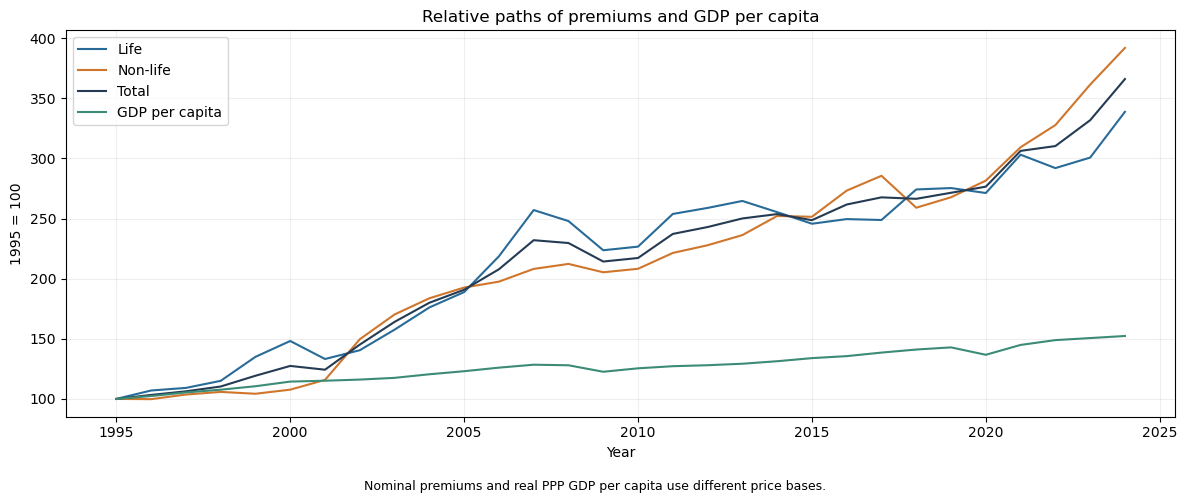

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))
for indicator, color in indicator_colors.items():
    rows = annual_trends.loc[annual_trends["indicator"].eq(indicator)]
    ax.plot(rows["year"], rows["index_1995"], color=color, label=indicator)
ax.set(title="Relative paths of premiums and GDP per capita", xlabel="Year", ylabel="1995 = 100")
ax.legend()
ax.grid(alpha=0.2)
fig.text(0.5, 0.01, "Nominal premiums and real PPP GDP per capita use different price bases.", ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.04, 1, 1])

plt.show()
plt.close(fig)

## 10. Pearson and Spearman correlations

Use the same 27 countries in both years for GWP, GWP per capita and direct premiums per capita. Pearson uses natural logs; Spearman compares ranks. This table contains correlation coefficients, not a formal test of differences between years.

In [11]:
correlation_rows = []
for comparison_year in comparison_years:
    for insurance_sector in insurance_sectors:
        country_data = direct_endpoint_panel.loc[
            direct_endpoint_panel["year"].eq(comparison_year)
            & direct_endpoint_panel["sector"].eq(insurance_sector)
        ]
        for premium_measure in ["gwp", "gwp_per_capita", "direct_per_capita"]:
            pearson_result = pearsonr(np.log(country_data["gdp_per_capita"]), np.log(country_data[premium_measure])).statistic
            spearman_result = spearmanr(country_data["gdp_per_capita"], country_data[premium_measure]).statistic
            correlation_rows.append({
                "year": comparison_year, "sector": insurance_sector, "outcome": premium_measure,
                "countries": len(country_data), "pearson_log": pearson_result, "spearman": spearman_result,
            })

correlation_results = pd.DataFrame(correlation_rows)
correlation_pdf_table = correlation_results.pivot(
    index=["year", "sector"], columns="outcome", values=["pearson_log", "spearman"]
)

correlation_pdf_table.columns = [method + "_" + outcome for method, outcome in correlation_pdf_table.columns]
correlation_pdf_table = correlation_pdf_table.reset_index()

outcome_order = ["gwp", "gwp_per_capita", "direct_per_capita"]
correlation_columns = [method + "_" + outcome for method in ["pearson_log", "spearman"] for outcome in outcome_order]
correlation_pdf_table = correlation_pdf_table[["year", "sector"] + correlation_columns]

display(correlation_pdf_table.round(3))

,year,sector,pearson_log_gwp,pearson_log_gwp_per_capita,pearson_log_direct_per_capita,spearman_gwp,spearman_gwp_per_capita,spearman_direct_per_capita
0,1995,Life,0.382,0.819,0.812,0.477,0.688,0.685
1,1995,Non-life,0.292,0.890,0.896,0.400,0.891,0.889
2,1995,Total,0.365,0.888,0.885,0.456,0.795,0.784
3,2024,Life,0.210,0.765,0.762,0.284,0.708,0.708
4,2024,Non-life,0.129,0.889,0.879,0.175,0.896,0.910
5,2024,Total,0.197,0.891,0.883,0.266,0.866,0.868


## 11. B1 and B2 regressions with HC3 intervals

Use combined Life + Non-life GWP in the same 28 countries.

- B1: log(GWP) = constant + coefficient * log(GDP per capita).
- B2: add log(population) to account for country size.

`cov_type="HC3"` provides heteroskedasticity-robust standard errors. **`use_t=True`** uses t-based confidence intervals, matching the R analysis. The intervals do not include imputation uncertainty. Associations across countries are not causal effects.

In [12]:
regression_rows = []
regression_models = {}

for comparison_year in comparison_years:
    country_data = endpoint_panel.loc[
        endpoint_panel["year"].eq(comparison_year) & endpoint_panel["sector"].eq("Total")
    ]
    outcome = np.log(country_data["gwp"])
    predictors_b1 = sm.add_constant(np.log(country_data[["gdp_per_capita"]]))
    predictors_b2 = sm.add_constant(np.log(country_data[["gdp_per_capita", "population"]]))
    model_b1 = sm.OLS(outcome, predictors_b1).fit(cov_type="HC3", use_t=True)
    model_b2 = sm.OLS(outcome, predictors_b2).fit(cov_type="HC3", use_t=True)
    regression_models[comparison_year] = {"B1": model_b1, "B2": model_b2}

    for model_name, model in regression_models[comparison_year].items():
        intervals = model.conf_int(alpha=0.05)
        for predictor in model.params.index:
            predictor_label = "(Intercept)" if predictor == "const" else f"log({predictor})"
            regression_rows.append({
                "year": comparison_year, "model": model_name, "predictor": predictor_label,
                "estimate": model.params[predictor], "standard_error_hc3": model.bse[predictor],
                "lower_95": intervals.loc[predictor, 0], "upper_95": intervals.loc[predictor, 1],
            })

regression_results = pd.DataFrame(regression_rows)
regression_pdf_table = regression_results.loc[
    regression_results["predictor"].ne("(Intercept)"),
    ["year", "model", "predictor", "estimate", "lower_95", "upper_95"],
].reset_index(drop=True)

display(regression_pdf_table.round(4))

,year,model,predictor,estimate,lower_95,upper_95
0,1995,B1,log(gdp_per_capita),1.5433,-0.0579,3.1445
1,1995,B2,log(gdp_per_capita),3.1666,2.4364,3.8969
2,1995,B2,log(population),1.1558,1.0152,1.2965
3,2024,B1,log(gdp_per_capita),0.8554,-0.7007,2.4116
4,2024,B2,log(gdp_per_capita),3.4011,2.4698,4.3323
5,2024,B2,log(population),1.2152,1.0885,1.3418


## 12. Leave-one-country-out B2 calculations

Remove one country at a time and refit B2. Keep separate Total, Life and Non-life results. No country is permanently removed. These checks examine dependence on individual countries, not all possible sources of model uncertainty.

In [13]:
leave_out_rows = []

for insurance_sector in ["Total", "Life", "Non-life"]:
    for comparison_year in comparison_years:
        country_data = endpoint_panel.loc[
            endpoint_panel["year"].eq(comparison_year) & endpoint_panel["sector"].eq(insurance_sector)
        ].reset_index(drop=True)
        outcome = np.log(country_data["gwp"])
        predictors = sm.add_constant(np.log(country_data[["gdp_per_capita", "population"]]))
        full_model = sm.OLS(outcome, predictors).fit()
        full_coefficient = full_model.params["gdp_per_capita"]

        for country_number in range(len(country_data)):
            reduced_data = country_data.drop(index=country_number)
            reduced_outcome = np.log(reduced_data["gwp"])
            reduced_predictors = sm.add_constant(np.log(reduced_data[["gdp_per_capita", "population"]]))
            reduced_model = sm.OLS(reduced_outcome, reduced_predictors).fit()
            reduced_coefficient = reduced_model.params["gdp_per_capita"]
            leave_out_rows.append({
                "sector": insurance_sector, "year": comparison_year,
                "omitted_country": country_data.loc[country_number, "country"],
                "full_coefficient": full_coefficient, "coefficient_after_omission": reduced_coefficient,
                "coefficient_change": reduced_coefficient - full_coefficient,
            })

leave_one_out_results = pd.DataFrame(leave_out_rows)
leave_one_out_summary = leave_one_out_results.groupby(["sector", "year"]).agg(
    minimum_coefficient=("coefficient_after_omission", "min"),
    maximum_coefficient=("coefficient_after_omission", "max"),
    all_coefficients_positive=("coefficient_after_omission", lambda values: values.gt(0).all()),
).reset_index()

display(leave_one_out_summary.round(4))

,sector,year,minimum_coefficient,maximum_coefficient,all_coefficients_positive
0,Life,1995,3.3413,3.9444,True
1,Life,2024,3.4161,4.1928,True
2,Non-life,1995,2.6786,2.9834,True
3,Non-life,2024,3.0213,3.3612,True
4,Total,1995,3.0168,3.3736,True
5,Total,2024,3.2379,3.7412,True


## 13. Plot Total, Life and Non-life country-omission checks

The horizontal position shows the change in the GDP coefficient after omitting a country. Zero means no change from the full sample. Both years use the same axis range and country order within each insurance sector.

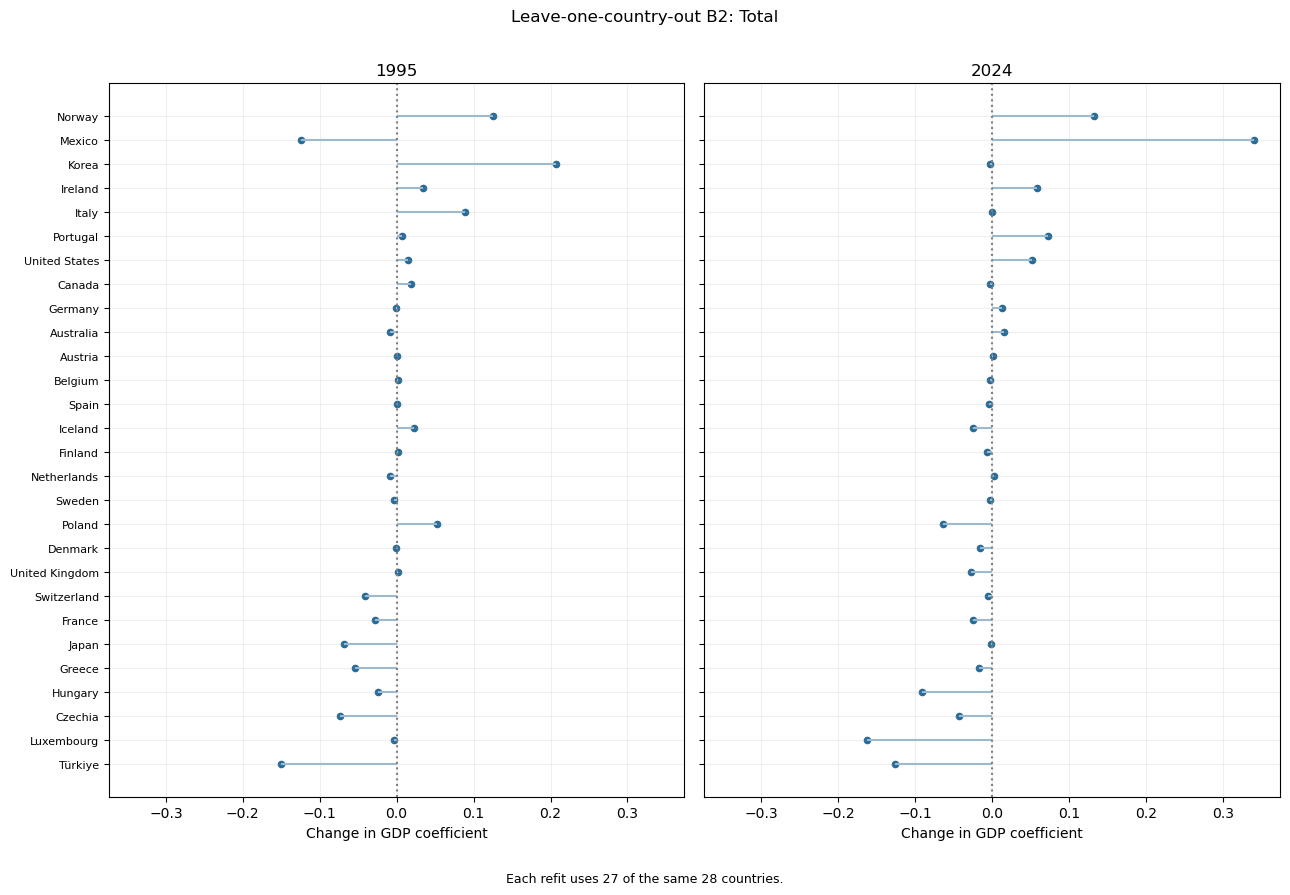

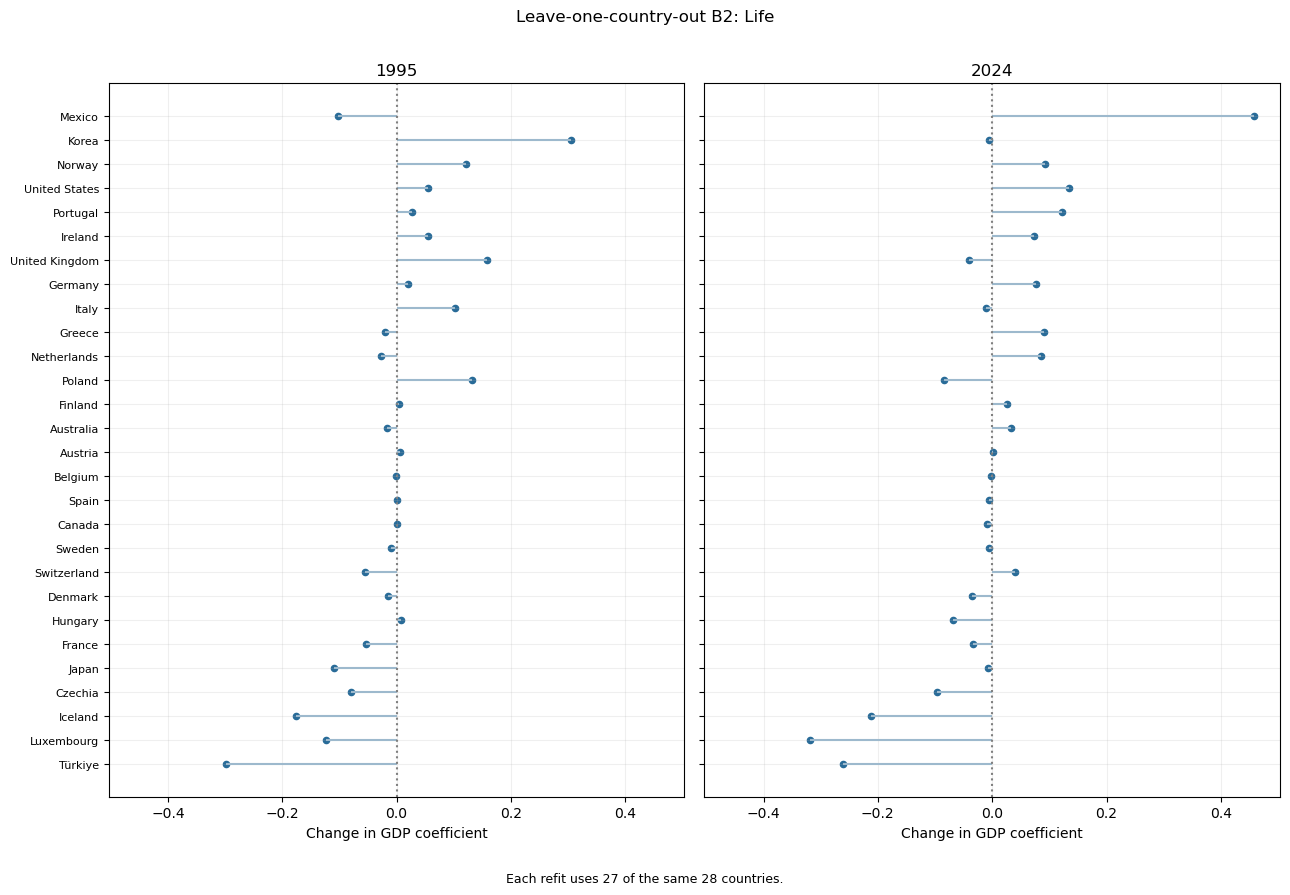

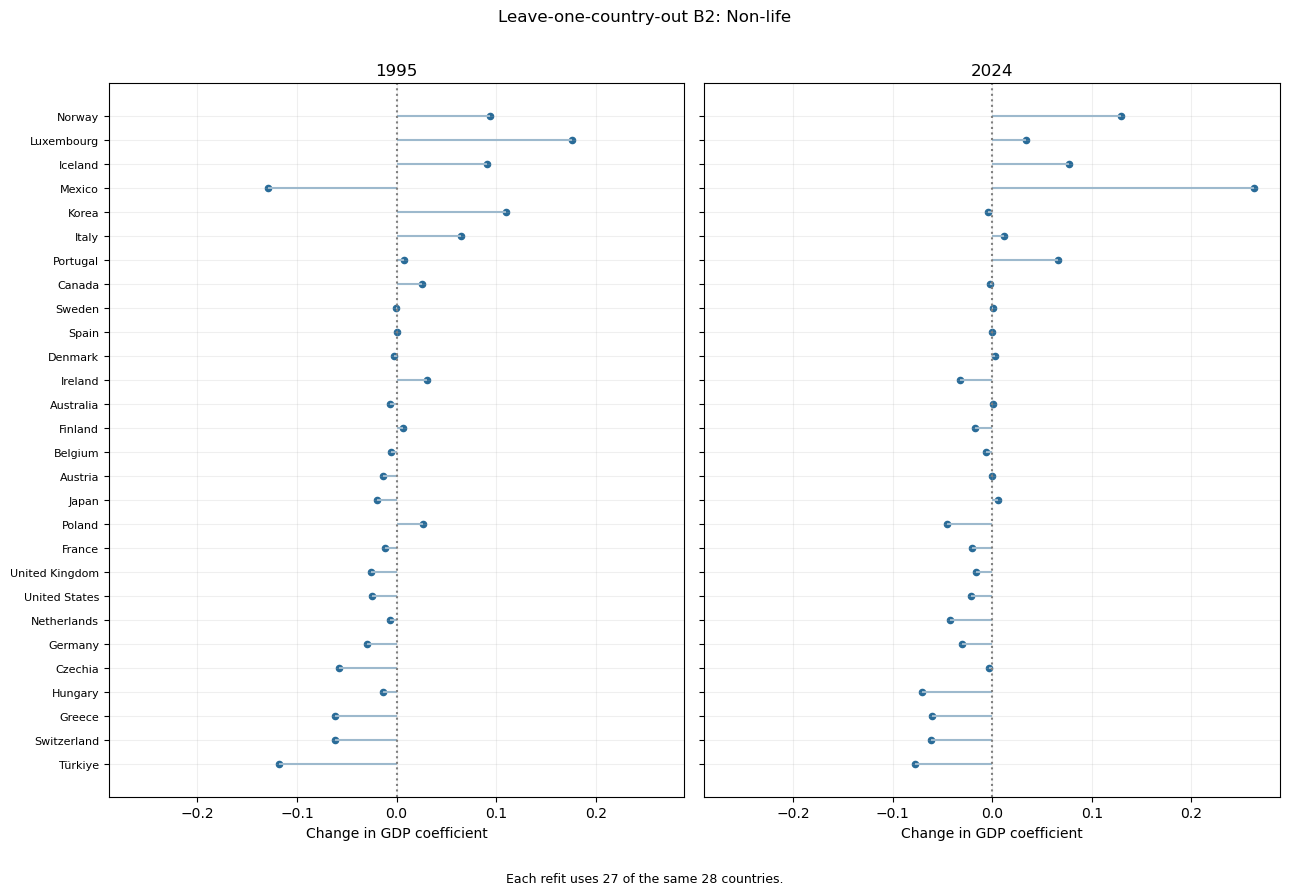

In [14]:
for insurance_sector in ["Total", "Life", "Non-life"]:
    sector_data = leave_one_out_results.loc[leave_one_out_results["sector"].eq(insurance_sector)]
    country_order = sector_data.groupby("omitted_country")["coefficient_change"].mean().sort_values().index.tolist()
    axis_limit = max(sector_data["coefficient_change"].abs().max() * 1.1, 0.01)
    fig, axes = plt.subplots(1, 2, figsize=(13, 9), sharey=True)
    for ax, comparison_year in zip(axes, comparison_years):
        rows = sector_data.loc[sector_data["year"].eq(comparison_year)].set_index("omitted_country").reindex(country_order)
        positions = np.arange(len(country_order))
        ax.hlines(positions, 0, rows["coefficient_change"], color="#9db9cd")
        ax.scatter(rows["coefficient_change"], positions, color="#286b98", s=20)
        ax.axvline(0, linestyle=":", color="grey")
        ax.set_yticks(positions, labels=country_order, fontsize=8)
        ax.set(title=str(comparison_year), xlim=(-axis_limit, axis_limit), xlabel="Change in GDP coefficient")
        ax.grid(alpha=0.2)
    fig.suptitle(f"Leave-one-country-out B2: {insurance_sector}")
    fig.text(0.5, 0.01, f"Each refit uses {len(gwp_country_codes) - 1} of the same {len(gwp_country_codes)} countries.",
             ha="center", fontsize=9)
    fig.tight_layout(rect=[0, 0.04, 1, 0.97])

    plt.show()
    plt.close(fig)

## Interpretation reminders

- Premiums are nominal USD; GDP per capita is real PPP. Their index paths do not measure real growth on a common price basis.
- Country comparisons do not show what happens when income changes within one country.
- GWP includes accepted reinsurance. Premiums per capita are not average resident spending.
- HC3 intervals account for heteroskedasticity, not imputation uncertainty.
